## Part A — DATA CLEANING (Q1–8 · 20 marks)

#### 1. Load the file and report its shape. Rename every column to snake_case (lowercase, no spaces, no brackets).


In [24]:
# Q1

import pandas as pd, numpy as np, re

raw = pd.read_csv('konnect_fibernet_churn_raw.csv', dtype=str, keep_default_na=False)
print('Raw shape:', raw.shape)
def snake(c):
    c = c.strip()
    c = re.sub(r'(?<=[a-z])(?=[A-Z])', '_', c)
    c = re.sub(r'[^0-9A-Za-z]+', '_', c).strip('_').lower()
    return c
df = raw.rename(columns=snake)

print(list(df.columns))

print(df.head())

Raw shape: (6180, 25)
['customer_id', 'signup_date', 'city', 'gender', 'age', 'senior_citizen', 'plan_type', 'contract', 'payment_method', 'tenure_months', 'monthly_charges', 'total_charges', 'ott_bundle', 'router_type', 'avg_download_speed_mbps', 'data_usage_gb', 'outages_6m', 'support_tickets_6m', 'avg_resolution_hrs', 'csat', 'last_complaint_category', 'pilot_group', 'speed_test_jun', 'speed_test_oct', 'churn']


The raw extract has 6,180 rows × 25 columns

Every column is now snake_case

#### 2. Find and remove duplicate customers. How many were there? Some duplicates differ only by whitespace — strip first, then de-duplicate.

In [25]:
# Q2
n_exact = df.duplicated().sum()
df = df.apply(lambda s: s.str.strip())
n_after_strip = df.duplicated().sum()
print('Duplicate rows :', n_exact)
print('duplicate rows after whitespace strip:', n_after_strip)
df = df.drop_duplicates().reset_index(drop=True)
print('shape after de-duplication:', df.shape)

Duplicate rows : 140
duplicate rows after whitespace strip: 180
shape after de-duplication: (6000, 25)


180 customers were duplicated out of which 140 were exact copies and 40 differed only by whitespace.

#### 3. Missing values are disguised as NA, null, ?, N/A, -, missing and blanks. Convert them all to NaN and print the missing count per column.

In [26]:
# Q3
MISSING = {'na','null','?','n/a','-','missing',''}
for c in df.columns:
    m = df[c].str.lower().isin(MISSING)
    df.loc[m, c] = np.nan                                
print(df.isna().sum()[lambda s: s>0])

age                         222
payment_method              175
total_charges               181
avg_download_speed_mbps     182
data_usage_gb               221
avg_resolution_hrs          324
csat                        397
last_complaint_category      94
speed_test_jun             5820
speed_test_oct             5820
dtype: int64


All seven disguises (NA, null, ?, N/A, -, missing, blank) are now NaN.

The word "None" in last_complaint_category is a real category (no complaint) and is deliberately not treated as missing.

#### 4. Standardise the categorical columns so each holds only its valid categories: city (watch for Bombay, Poona, Nasik, Chh. Sambhajinagar), gender, contract, plan_type, ott_bundle, churn. Encode ott_bundle and churn as 1/0.

In [27]:
# Q4
city_map = {'bombay':'Mumbai','mumbai':'Mumbai','poona':'Pune','pune':'Pune','nasik':'Nashik','nashik':'Nashik',
            'chh. sambhajinagar':'Aurangabad','aurangabad':'Aurangabad','nagpur':'Nagpur'}
df['city'] = df.city.str.lower().map(city_map)
df['gender'] = df.gender.str.lower().str[0].map({'m':'Male','f':'Female'})
df['contract'] = df.contract.str.lower().map({'monthly':'Monthly','m2m':'Monthly','month-to-month':'Monthly',
    'quarterly':'Quarterly','3 months':'Quarterly','annual':'Annual','yearly':'Annual','12 months':'Annual'})
def plan(s):
    s = s.lower()
    return ('Basic 50 Mbps' if 'basic' in s else 'Standard 100 Mbps' if ('std' in s or 'standard' in s)
            else 'Premium 300 Mbps' if 'premium' in s else 'Ultra 1 Gbps' if 'ultra' in s else np.nan)
df['plan_type'] = df.plan_type.map(plan)
yn = {'yes':1,'y':1,'true':1,'1':1,'no':0,'n':0,'false':0,'0':0}
df['ott_bundle'] = df.ott_bundle.str.lower().map(yn).astype('Int64')
df['churn'] = df.churn.str.lower().map(yn).astype('Int64')
for c in ['city','gender','contract','plan_type','ott_bundle','churn']:
    print(c, {str(k): int(v) for k, v in df[c].value_counts(dropna=False).items()})

city {'Pune': 1743, 'Mumbai': 1668, 'Nashik': 943, 'Nagpur': 890, 'Aurangabad': 756}
gender {'Male': 3376, 'Female': 2624}
contract {'Monthly': 3053, 'Annual': 1597, 'Quarterly': 1350}
plan_type {'Standard 100 Mbps': 2238, 'Basic 50 Mbps': 1812, 'Premium 300 Mbps': 1302, 'Ultra 1 Gbps': 648}
ott_bundle {'0': 3450, '1': 2550}
churn {'0': 3996, '1': 2004}


Each categorical column now has only its valid levels

5 cities (Mumbai,Pune, Nashik,Aurangabad),
2 genders,
3 contracts,
4 plans,
ott_bundle and churn are 1/0.

#### 5. Convert monthly_charges and total_charges to numbers (strip ₹, Rs., commas, spaces). Convert csat to an integer 1–5 (some values look like "4/5" or "4 stars").


In [28]:
# Q5
def to_money(s):
    return pd.to_numeric(s.str.replace(r'(?i)rs\.?|₹|,|\s','',regex=True), errors='coerce')
df['monthly_charges'] = to_money(df.monthly_charges)
df['total_charges'] = to_money(df.total_charges)
df['csat'] = pd.to_numeric(df.csat.str.extract(r'^(\d)')[0], errors='coerce').astype('Int64')
assert df.csat.dropna().between(1,5).all()
print(df[['monthly_charges','total_charges']].describe().round(1)); print('csat counts:', {('NA' if pd.isna(k) else int(k)): int(v) for k, v in df.csat.value_counts(dropna=False).sort_index().items()})
# remaining numeric columns arrive as text -> convert
for c in ['age','senior_citizen','tenure_months','avg_download_speed_mbps','data_usage_gb','outages_6m',
          'support_tickets_6m','avg_resolution_hrs','speed_test_jun','speed_test_oct']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

       monthly_charges  total_charges
count           6000.0         5819.0
mean             971.0        23857.8
std              385.2        18947.9
min              476.1          482.3
25%              701.2        10268.3
50%              832.6        19684.0
75%             1155.7        31650.4
max             2015.3       137489.2
csat counts: {1: 94, 2: 613, 3: 1847, 4: 2200, 5: 849, 'NA': 397}


monthly_charges and total_charges are numeric once ₹, Rs., commas and spaces are stripped 

csat is integer 1–5, 397 values remain missing.

#### 6. Parse signup_date — it appears in at least six formats. Which format is genuinely ambiguous, and what assumption did you make?

In [29]:
# Q6
def fmt_name(s):
    if re.fullmatch(r'\d{4}-\d{2}-\d{2}', s): return 'YYYY-MM-DD'
    if re.fullmatch(r'\d{2}\.\d{2}\.\d{4}', s): return 'DD.MM.YYYY'
    if re.fullmatch(r'\d{2}-[A-Za-z]{3}-\d{4}', s): return 'DD-Mon-YYYY'
    if re.fullmatch(r'\d{2}/\d{2}/\d{4}', s): return 'NN/NN/YYYY (slash)'
    if re.fullmatch(r'[A-Za-z]{3} \d{2}, \d{4}', s): return 'Mon DD, YYYY'
    if re.fullmatch(r'[A-Za-z]{4,} \d{2}, \d{4}', s): return 'Month DD, YYYY'
    return 'other'
fm = df.signup_date.dropna().map(fmt_name)
print(fm.value_counts())
sl = df.signup_date[df.signup_date.fillna('').str.fullmatch(r'\d{2}/\d{2}/\d{4}')]
a, b = sl.str[:2].astype(int), sl.str[3:5].astype(int)
print(f'slash dates: {len(sl)} | first>12 (must be DD/MM): {(a>12).sum()} | second>12 (must be MM/DD): {(b>12).sum()} | truly ambiguous (both<=12 & day!=month): {((a<=12)&(b<=12)&(a!=b)).sum()}')

def parse_one(s):
    if pd.isna(s): return pd.NaT, 'missing'
    for f, n in [('%Y-%m-%d','iso'),('%d.%m.%Y','dot'),('%d-%b-%Y','dmon'),('%B %d, %Y','longmonth'),('%b %d, %Y','shortmonth')]:
        try: return pd.to_datetime(s, format=f), n
        except Exception: pass
    x, y, z = map(int, re.fullmatch(r'(\d{2})/(\d{2})/(\d{4})', s).groups())
    if x > 12: return pd.Timestamp(z, y, x), 'slash_dmy_forced'
    if y > 12: return pd.Timestamp(z, x, y), 'slash_mdy_forced'
    return pd.NaT, 'slash_ambiguous'
res = df.signup_date.map(parse_one)
df['signup_date_parsed'] = [r[0] for r in res]; df['_how'] = [r[1] for r in res]
# Reference month implied by tenure on rows where the date is unambiguous
REF = pd.Timestamp('2026-10-01')
months = lambda d: (REF.year-d.dt.year)*12 + (REF.month-d.dt.month)
ok = df.signup_date_parsed.notna() & df.tenure_months.between(0,120)
print('implied tenure - recorded tenure (unambiguous dates):', (months(df.signup_date_parsed)-df.tenure_months)[ok].value_counts().head(3).to_dict(), '-> reference month = Oct-2026')
# resolve ambiguous slash dates: DD/MM by default (Indian convention, 71% of forced slash dates); use MM/DD only if tenure clearly says so
amb = df._how.eq('slash_ambiguous')
x = df.signup_date[amb].str[:2].astype(int); y = df.signup_date[amb].str[3:5].astype(int); z = df.signup_date[amb].str[6:].astype(int)
d_dmy = pd.to_datetime(dict(year=z, month=y, day=x)); d_mdy = pd.to_datetime(dict(year=z, month=x, day=y))
t = df.tenure_months[amb]; valid_t = t.between(0,120)
e_dmy = (REF.year-d_dmy.dt.year)*12+(REF.month-d_dmy.dt.month); e_mdy = (REF.year-d_mdy.dt.year)*12+(REF.month-d_mdy.dt.month)
use_mdy = valid_t & ((e_mdy-t).abs() < (e_dmy-t).abs())
df.loc[amb, 'signup_date_parsed'] = np.where(use_mdy, d_mdy, d_dmy)
print(f'ambiguous slash rows: {amb.sum()} -> read as MM/DD only when tenure supports it: {use_mdy.sum()}; DD/MM: {(~use_mdy).sum()}')
df['signup_date'] = df.signup_date_parsed; df = df.drop(columns=['signup_date_parsed','_how'])
print('parsed range:', df.signup_date.min().date(), '->', df.signup_date.max().date(), '| unparsed:', df.signup_date.isna().sum())

signup_date
YYYY-MM-DD            2773
NN/NN/YYYY (slash)    1593
DD-Mon-YYYY            729
DD.MM.YYYY             499
Month DD, YYYY         360
Mon DD, YYYY            46
Name: count, dtype: int64
slash dates: 1593 | first>12 (must be DD/MM): 732 | second>12 (must be MM/DD): 300 | truly ambiguous (both<=12 & day!=month): 529
implied tenure - recorded tenure (unambiguous dates): {0.0: 5299, -1.0: 137, 15.0: 1} -> reference month = Oct-2026
ambiguous slash rows: 561 -> read as MM/DD only when tenure supports it: 150; DD/MM: 411
parsed range: 2020-11-06 -> 2026-09-30 | unparsed: 0


Six formats were found: YYYY-MM-DD, DD.MM.YYYY, DD-Mon-YYYY, Month DD, YYYY, Mon DD, YYYY and the slash format NN/NN/YYYY, which is the genuinely ambiguous one. Among slash dates that can be decided (a part > 12), 732 are DD/MM and 300 are MM/DD — so two source systems feed this format. 561 slash dates have both parts ≤ 12 (e.g. 04/08/2026).

Assumption: default to DD/MM, but switch to MM/DD where the recorded tenure_months clearly agrees only with that reading. Tenure is an independent check: for unambiguous dates it equals the months to Oct 2026 for 5,299 of 5,437 rows (137 are off by one), so the reference month is solid. 150 ambiguous dates were read as MM/DD, 411 as DD/MM. All 6,000 dates parse (Nov 2020 – Sep 2026).

#### 7. Find the impossible values in age, tenure and resolution hours. Say what you did with each and why.

In [30]:
# Q7
imp = {}
bad_age = (df.age<18)|(df.age>100); imp['age <18 or >100']=(int(bad_age.sum()), [float(v) for v in sorted(df.age[bad_age].unique())])
bad_ten = (df.tenure_months<0)|(df.tenure_months>120)|((df.tenure_months==0)&(months(df.signup_date)>1))
imp['tenure <0, >120, or 0 contradicting signup date'] = (int(bad_ten.sum()), [float(v) for v in sorted(df.tenure_months[bad_ten].unique())])
print(df.loc[df.avg_resolution_hrs>100,'avg_resolution_hrs'].tolist(), df.avg_resolution_hrs.quantile([.5,.99]).tolist())
bad_res = (df.avg_resolution_hrs<=0)|(df.avg_resolution_hrs>720)
imp['resolution hrs <=0 or >720 (30 days)']=(int(bad_res.sum()), [float(v) for v in sorted(df.avg_resolution_hrs[bad_res].unique())])
for k,v in imp.items(): print(k, '->', v)
df.loc[bad_age,'age'] = np.nan
df.loc[bad_ten,'tenure_months'] = months(df.signup_date)[bad_ten]     # rebuilt from signup date (independent, verified column)
df.loc[bad_res,'avg_resolution_hrs'] = np.nan
print('tenure after repair:', df.tenure_months.describe()[['min','max']].tolist())
# senior flag vs age
print(pd.crosstab(df.age>=60, df.senior_citizen, margins=True))

[999.0, 1200.0] [17.7, 55.25]
age <18 or >100 -> (5, [-3.0, 0.0, 7.0, 150.0, 212.0])
tenure <0, >120, or 0 contradicting signup date -> (3, [-2.0, 0.0, 840.0])
resolution hrs <=0 or >720 (30 days) -> (4, [-4.0, 0.0, 999.0, 1200.0])
tenure after repair: [1.0, 71.0]
senior_citizen     0    1   All
age                            
False           5873    5  5878
True               0  122   122
All             5873  127  6000


Age - 5 impossible values (−3, 0, 7, 150, 212): set to NaN (a broadband account holder must be an adult, and no one is 150). The 5 customers flagged senior_citizen = 1 with a missing age are left as flagged; there is no contradiction elsewhere.

Tenure - 3 bad values (−2, 0 and 840 months = 70 years). Rather than delete the customers, tenure was rebuilt from signup_date, which we just verified agrees with tenure for ~97% of rows; repaired values lie in 1–71 months. (One row's signup date disagrees with its tenure by 15 months; we cannot tell which is wrong, so it is left alone — immaterial for 6,000 rows.)

Resolution hours - 4 impossible values (−4, 0, 999, 1200; the 99th percentile is 55 h): set to NaN. 999 looks like a sentinel code and 1,200 h is 50 days. Genuine extremes (e.g. 100+ GB heavy users) are kept — they are valid data, not errors.

#### 8. Decide, column by column, how you handle the remaining missing values (drop / median / mode / leave as NaN) and justify it. Explain why you must not impute speed_test_jun and speed_test_oct. Save the result as konnect_churn_clean.csv.

In [31]:
# Q8
miss = df.isna().sum(); miss = miss[miss>0]
decision = pd.DataFrame({'n_missing':miss, 'pct':(miss/len(df)*100).round(1)})
decision['decision'] = pd.Series({
 'age':'median impute (symmetric, descriptive covariate only)',
 'payment_method':'leave NaN (no honest default; excluded from Q22)',
 'total_charges':'leave NaN (derived = tenure x monthly; not tested)',
 'avg_download_speed_mbps':'median within plan (speed is set by plan)',
 'data_usage_gb':'leave NaN (right-skewed, shape is analysed in Q12)',
 'avg_resolution_hrs':'leave NaN (outcome in Q25/Q30; constant fill would shrink variance)',
 'csat':'leave NaN (outcome in Q26/Q28; never invent a satisfaction score)',
 'last_complaint_category':'leave NaN (excluded from Q24)',
 'speed_test_jun':'leave NaN - structural (non-pilot) - NEVER impute',
 'speed_test_oct':'leave NaN - structural (non-pilot) - NEVER impute'})
print(decision.to_string())
df['age'] = df.age.fillna(df.age.median())
df['avg_download_speed_mbps'] = df.avg_download_speed_mbps.fillna(df.groupby('plan_type').avg_download_speed_mbps.transform('median'))
print('rows dropped for missing target (churn):', df.churn.isna().sum())
pil = df[df.pilot_group=='Yes']
print('pilot customers:', len(pil), '| missing jun/oct among pilot:', pil.speed_test_jun.isna().sum(), pil.speed_test_oct.isna().sum(),
      '| non-pilot with a speed test:', df[df.pilot_group!='Yes'].speed_test_jun.notna().sum())
df.to_csv('konnect_churn_clean.csv', index=False)
print('saved', df.shape)

                         n_missing   pct                                                             decision
age                            227   3.8                median impute (symmetric, descriptive covariate only)
payment_method                 175   2.9                     leave NaN (no honest default; excluded from Q22)
total_charges                  181   3.0                   leave NaN (derived = tenure x monthly; not tested)
avg_download_speed_mbps        182   3.0                            median within plan (speed is set by plan)
data_usage_gb                  221   3.7                   leave NaN (right-skewed, shape is analysed in Q12)
avg_resolution_hrs             328   5.5  leave NaN (outcome in Q25/Q30; constant fill would shrink variance)
csat                           397   6.6    leave NaN (outcome in Q26/Q28; never invent a satisfaction score)
last_complaint_category         94   1.6                                        leave NaN (excluded from Q24)
speed_test

Rule used: impute only when the variable is a descriptive covariate and a sensible central value exists; never fill a variable that is itself being tested. No rows were dropped (no missing target).

Why speed_test_jun / speed_test_oct must NOT be imputed: they exist only for the 180 pilot customers — the other 5,820 never took the test, so their "missing" is structural, not accidental. All 180 pilot customers have both readings, so there is nothing to impute inside the pilot either. 

Saved as konnect_churn_clean.csv (6,000 × 25).

### Part B — EXPLORATORY DATA ANALYSIS

#### 9. What is the overall churn rate?

In [32]:
# Q9
n, k = len(df), int(df.churn.sum()); rate = k / n
print(f'Churned: {k:,} of {n:,} customers = {rate:.1%}  ')

Churned: 2,004 of 6,000 customers = 33.4%  


One in three customers left: 33.4%

#### 10. Churn rate by contract type, plan type, payment method, OTT bundle, router type, city and gender — a table or bar chart for each. Which three factors look most important at first glance?

--- contract ---


,churn_rate,customers
contract,,
Annual,14.1,1597
Monthly,47.1,3053
Quarterly,25.2,1350


--- plan_type ---


,churn_rate,customers
plan_type,,
Basic 50 Mbps,27.6,1812
Premium 300 Mbps,37.5,1302
Standard 100 Mbps,31.8,2238
Ultra 1 Gbps,47.1,648


--- payment_method ---


,churn_rate,customers
payment_method,,
Cash/Cheque,42.6,1011
Credit Card,34.0,1269
Net Banking,30.6,1173
UPI AutoPay,30.5,2372


... (4 outputs left out)

--- city ---


,churn_rate,customers
city,,
Aurangabad,31.6,756
Mumbai,31.8,1668
Nagpur,36.0,890
Nashik,34.0,943
Pune,34.0,1743


--- gender ---


,churn_rate,customers
gender,,
Female,33.5,2624
Male,33.4,3376


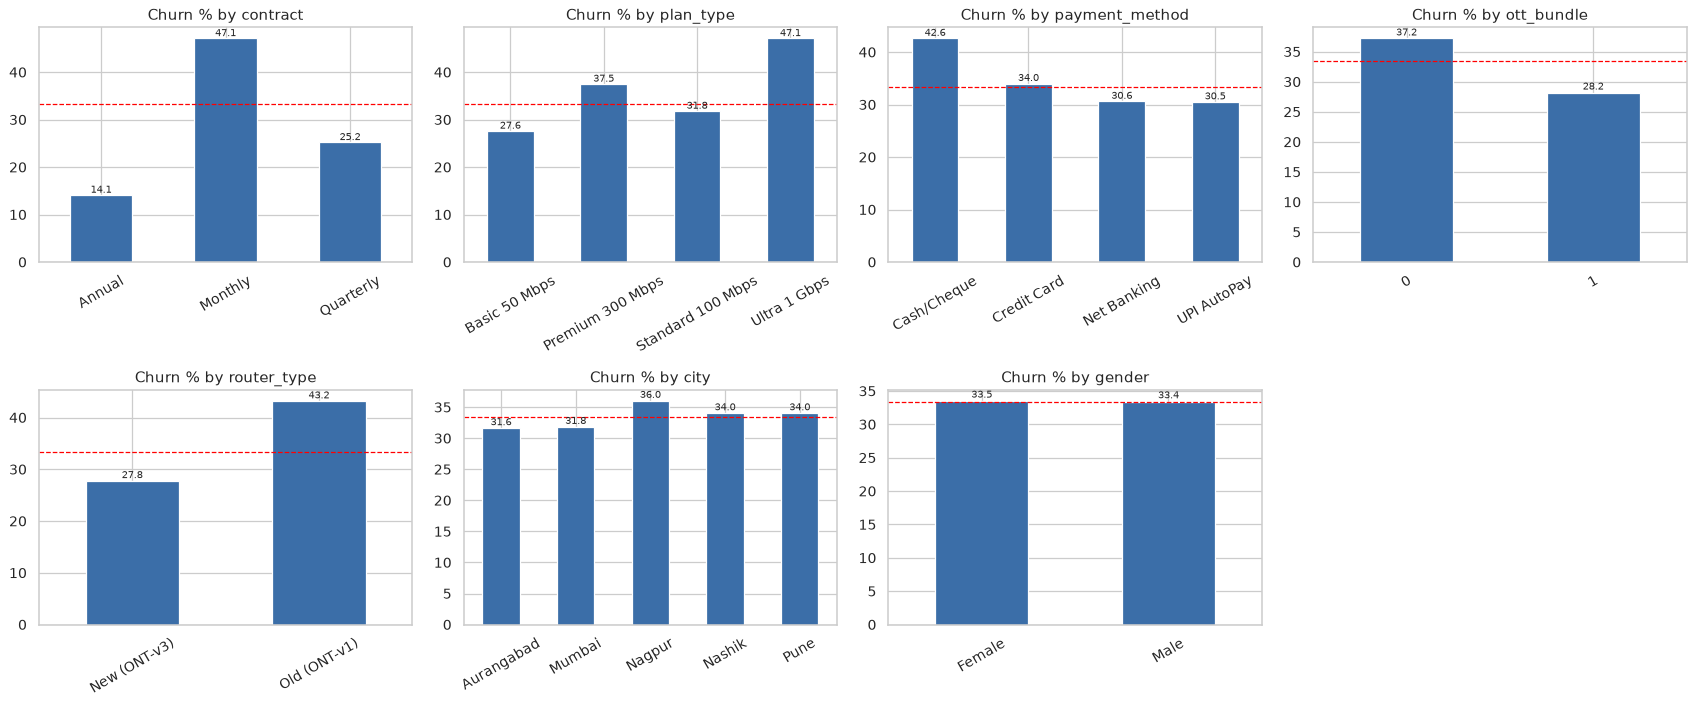

Ranking of factors (dashed red line = overall churn):


,factor,spread_pp (max-min),cramers_v,chi2_p
0,contract,33.0,0.308,5.686e-124
4,router_type,15.4,0.156,1.446e-33
1,plan_type,19.5,0.125,2.606e-20
2,payment_method,12.1,0.094,3.139e-11
3,ott_bundle,9.0,0.094,3.738e-13
5,city,4.4,0.032,0.1983
6,gender,0.1,0.001,0.9523


In [33]:
# Q10
factors = ['contract','plan_type','payment_method','ott_bundle','router_type','city','gender']
fig, axes = plt.subplots(2, 4, figsize=(19, 8)); axes = axes.ravel()
summary = []
for ax, f in zip(axes, factors):
    t = df.groupby(f).churn.agg(churn_rate='mean', customers='size')
    t['churn_rate'] = (t.churn_rate*100).round(1)
    print(f'--- {f} ---'); display(t)
    t.churn_rate.plot.bar(ax=ax, color='#3b6ea8'); ax.axhline(rate*100, color='red', ls='--', lw=1)
    ax.set_title(f'Churn % by {f}'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=30)
    for i, v in enumerate(t.churn_rate): ax.text(i, v+0.5, f'{v}', ha='center', fontsize=8)
    ct = pd.crosstab(df[f], df.churn)
    summary.append((f, t.churn_rate.max()-t.churn_rate.min(), cramers_v(ct), stats.chi2_contingency(ct)[1]))
axes[-1].axis('off'); plt.tight_layout(); plt.show()
rank = pd.DataFrame(summary, columns=['factor','spread_pp (max-min)','cramers_v','chi2_p']).sort_values('cramers_v', ascending=False)
rank['chi2_p'] = rank.chi2_p.map(p4); print('Ranking of factors (dashed red line = overall churn):'); display(rank.round(3))

Three most important factors are contract type (Monthly 47.1% vs Annual 14.1%; V = 0.31), router type (Old 43.2% vs New 27.8%; V = 0.16) and plan type (Ultra 47.1% vs Basic 27.6%; V = 0.13). 

Payment method (Cash/Cheque 42.6%) and OTT bundle (28.2% with vs 37.2% without) follow closely (V ≈ 0.09).

City differences are small (31.6%–36.0%, not significant, p = 0.198) and gender shows none (33.5% vs 33.4%).

#### 11. Compare churners and stayers on the mean AND median of tenure, monthly charges, outages, support tickets, resolution hours and CSAT. Which differences look large?

In [34]:
# Q11
num = ['tenure_months','monthly_charges','outages_6m','support_tickets_6m','avg_resolution_hrs','csat']
g = df.groupby('churn')[num]
cmp_ = pd.concat({'mean_stay': g.mean().loc[0], 'mean_churn': g.mean().loc[1], 'median_stay': g.median().loc[0], 'median_churn': g.median().loc[1]}, axis=1)
cmp_['diff_in_mean'] = cmp_.mean_churn - cmp_.mean_stay
cmp_['std_diff_d'] = [cohens_d(df.loc[df.churn==1, c].dropna(), df.loc[df.churn==0, c].dropna()) for c in num]
display(cmp_.round(2))

,mean_stay,mean_churn,median_stay,median_churn,diff_in_mean,std_diff_d
tenure_months,28.33,18.73,27.0,17.0,-9.6,-0.61
monthly_charges,942.35,1028.16,823.74,918.46,85.81,0.22
outages_6m,1.86,2.76,2.0,3.0,0.89,0.56
support_tickets_6m,1.56,2.2,1.0,2.0,0.64,0.41
avg_resolution_hrs,19.41,20.99,17.4,18.5,1.58,0.14
csat,3.83,3.0,4.0,3.0,-0.83,-0.98


The large differences are CSAT (3.00 vs 3.83; d ≈ −1.0), tenure (median 17 vs 27 months; d = −0.61) and outages (2.76 vs 1.86; d = 0.56); support tickets are moderate (2.20 vs 1.56; d = 0.41). 

Monthly charges differ modestly and in the opposite direction to the Marketing claim (churners pay ₹86 more; d = 0.22), and resolution hours barely differ (+1.6 h; d = 0.14). Means and medians tell the same story.

#### 12. Histogram and box plot for avg_resolution_hrs, support_tickets_6m and data_usage_gb. Comment on skewness and flag outliers with the 1.5 × IQR rule. Are these variables normal?

/tmp/ipykernel_602815/488070516.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, j].boxplot(x, vert=False, flierprops=dict(marker='.', markersize=3)); axes[1, j].set_title(f'{c} (box plot)')
/tmp/ipykernel_602815/488070516.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, j].boxplot(x, vert=False, flierprops=dict(marker='.', markersize=3)); axes[1, j].set_title(f'{c} (box plot)')
/tmp/ipykernel_602815/488070516.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, j].boxplot(x, vert=False, flierprops=dict(marker='.', markersize=3)); axes[1, j].set_title(f'{c} (box plot)')


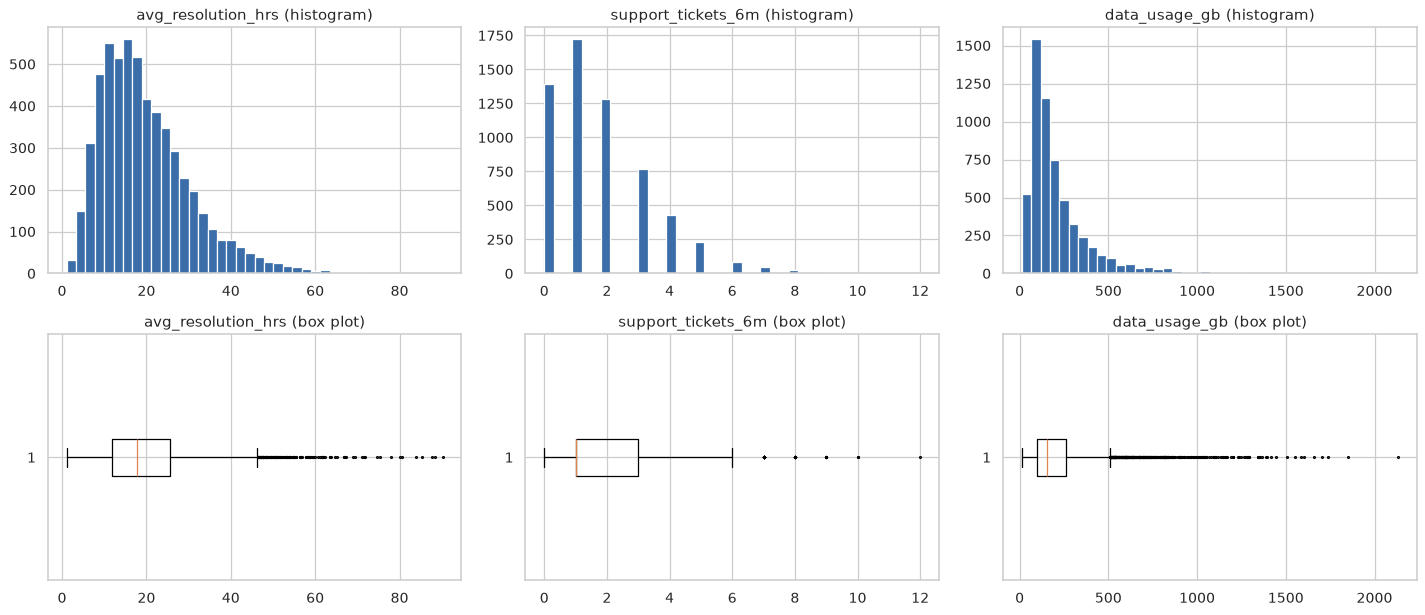

,variable,n,mean,median,skew,excess_kurtosis,lower_fence,upper_fence,n_outliers,pct_outliers,dagostino_p
0,avg_resolution_hrs,5672,19.94,17.7,1.33,2.92,-8.90,46.30,160,2.82,2.182e-306
1,support_tickets_6m,6000,1.77,1.0,1.19,1.77,-2.00,6.00,84,1.40,5.716e-253
2,data_usage_gb,5779,216.96,152.9,2.82,11.55,-148.62,507.58,426,7.37,0


In [35]:
# Q12
cols = ['avg_resolution_hrs','support_tickets_6m','data_usage_gb']
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
rows = []
for j, c in enumerate(cols):
    x = df[c].dropna()
    axes[0, j].hist(x, bins=40, color='#3b6ea8'); axes[0, j].set_title(f'{c} (histogram)')
    axes[1, j].boxplot(x, vert=False, flierprops=dict(marker='.', markersize=3)); axes[1, j].set_title(f'{c} (box plot)')
    q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1; lo_f, hi_f = q1 - 1.5*iqr, q3 + 1.5*iqr
    out = ((x < lo_f) | (x > hi_f)).sum()
    rows.append([c, len(x), x.mean(), x.median(), x.skew(), x.kurt(), lo_f, hi_f, out, out/len(x)*100, stats.normaltest(x)[1]])
plt.tight_layout(); plt.show()
res = pd.DataFrame(rows, columns=['variable','n','mean','median','skew','excess_kurtosis','lower_fence','upper_fence','n_outliers','pct_outliers','dagostino_p'])
res['dagostino_p'] = res.dagostino_p.map(p4); display(res.round(2))

All three variables are right-skewed (resolution hours 1.33, tickets 1.19, data usage 2.82) and not normal (D'Agostino p ≈ 0; the box plots are lopsided, the means exceed the medians). 

The 1.5×IQR rule flags 160 resolution-time outliers (2.8%, above 46 h), 84 ticket outliers (1.4%, above 6 tickets) and 426 data-usage outliers (7.4%, above 508 GB). 

These are real long tails (slow cases, heavy users), not errors, so they are kept and handled with rank-based tests where it matters.

#### 13. Correlation heat map of the numeric variables. Which pairs are strongly related? Which strong correlation exists only "by construction" and must not be reported as an insight?

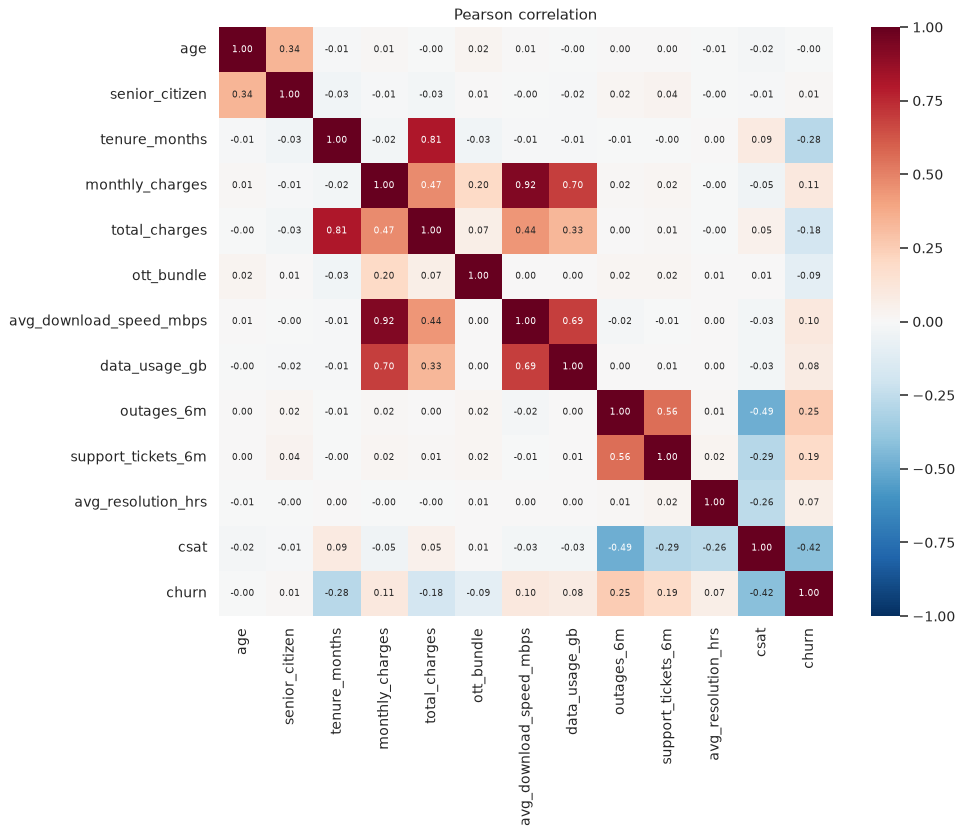

,level_0,level_1,r
0,monthly_charges,avg_download_speed_mbps,0.92
1,tenure_months,total_charges,0.81
2,monthly_charges,data_usage_gb,0.70
3,avg_download_speed_mbps,data_usage_gb,0.69
4,outages_6m,support_tickets_6m,0.56
5,outages_6m,csat,-0.49
6,monthly_charges,total_charges,0.47
7,total_charges,avg_download_speed_mbps,0.44
8,csat,churn,-0.42


total_charges / (tenure x monthly_charges):  median = 0.985, IQR = 0.977-0.992  -> total_charges is essentially tenure x monthly bill


In [36]:
# Q13
numcols = ['age','senior_citizen','tenure_months','monthly_charges','total_charges','ott_bundle','avg_download_speed_mbps',
           'data_usage_gb','outages_6m','support_tickets_6m','avg_resolution_hrs','csat','churn']   # pilot-only speed tests excluded (97% structurally empty)
corr = df[numcols].astype(float).corr()
plt.figure(figsize=(11, 8.5)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot_kws={'size': 7}); plt.title('Pearson correlation'); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().rename('r').reset_index()
display(pairs[pairs.r.abs() >= 0.40].sort_values('r', key=abs, ascending=False).round(2).reset_index(drop=True))
ratio = (df.total_charges / (df.tenure_months * df.monthly_charges)).describe()
print('total_charges / (tenure x monthly_charges):  median = %.3f, IQR = %.3f-%.3f  -> total_charges is essentially tenure x monthly bill' % (ratio['50%'], ratio['25%'], ratio['75%']))

Strong pairs: monthly charges–speed (0.92) and monthly charges–data usage (0.70), speed–usage (0.69) — all because the plan sets bill, speed and usage together; tenure–total charges (0.81); outages–tickets (0.56); outages–CSAT (−0.49). The most useful link to churn is CSAT (−0.42).

Correlation that exists "by construction": total_charges vs tenure_months (0.81). Total billed ≈ tenure × monthly charge (the ratio is 0.985 with a very narrow spread), so it is arithmetic, not an insight; total_charges vs monthly_charges (0.47) is the same mechanism. The pilot-only speed tests were excluded from the map (97% empty).

#### 14. Find one high-risk segment (2–3 conditions combined) with churn above 60%, and one low-risk segment with churn below 15%. Give the size of each.

In [37]:
# Q14
high = (df.contract=='Monthly') & (df.router_type.str.startswith('Old')) & (df.csat <= 3)
low  = (df.contract=='Annual') & (df.csat >= 4) & (df.tenure_months >= 24)
for name, m in [('HIGH-RISK: Monthly contract + Old router + CSAT <= 3', high), ('LOW-RISK: Annual contract + CSAT >= 4 + tenure >= 24 months', low)]:
    s = df[m]; lo, hi = proportion_confint(int(s.churn.sum()), len(s), method='wilson')
    print(f'{name}\n   customers = {len(s):,} ({len(s)/len(df):.1%} of base) | churn = {s.churn.mean():.1%} (95% CI {lo:.1%}-{hi:.1%}) | churners = {int(s.churn.sum()):,} ({s.churn.sum()/df.churn.sum():.1%} of all churners)')

HIGH-RISK: Monthly contract + Old router + CSAT <= 3
   customers = 676 (11.3% of base) | churn = 71.4% (95% CI 67.9%-74.7%) | churners = 483 (24.1% of all churners)
LOW-RISK: Annual contract + CSAT >= 4 + tenure >= 24 months
   customers = 693 (11.6% of base) | churn = 4.8% (95% CI 3.4%-6.6%) | churners = 33 (1.6% of all churners)


High-risk: Monthly contract + Old router + CSAT ≤ 3 -> 676 customers (11.3% of the base) with 71.4% churn — they hold 24% of all churners. 

Low-risk: Annual contract + CSAT ≥ 4 + tenure ≥ 24 months -> 693 customers (11.6%) with 4.8% churn. The same size of customer group differs 15-fold in churn, so retention effort should be steered by segment, not spread evenly.

### Part C — TEST THE BOARD'S CLAIMS

#### 15. Sales: "Our churn equals the 30% industry rate." → one-proportion z-test.

(i) Hypotheses: H₀: p = 0.30; H₁: p ≠ 0.30 (two-sided).

(ii) Test: One-proportion z-test: one sample, binary outcome compared with a known benchmark.

In [38]:
# Q15
n, k = len(df), int(df.churn.sum()); p_hat, p0 = k/n, 0.30
print(f'(iii) Assumptions: n*p0 = {n*p0:,.0f}, n*(1-p0) = {n*(1-p0):,.0f}  (both >= 10 -> normal approximation valid; customers independent)')
z = (p_hat - p0) / np.sqrt(p0*(1-p0)/n); p = 2*stats.norm.sf(abs(z))
z2, p2 = proportions_ztest(k, n, p0, prop_var=p0)
print(f'(iv) p_hat = {p_hat:.4f}, z = {z:.3f}, p-value = {p4(p)}   (statsmodels check: z = {z2:.3f}, p = {p4(p2)})')
lo, hi = proportion_confint(k, n, method='wilson'); h = 2*np.arcsin(np.sqrt(p_hat)) - 2*np.arcsin(np.sqrt(p0))
print(f'(v)  Gap = {(p_hat-p0)*100:.2f} percentage points; 95% CI for churn = [{lo:.4f}, {hi:.4f}]; Cohen h = {h:.3f}')
print(f'     Excess churners vs benchmark = {(p_hat-p0)*n:,.0f} customers = Rs {(p_hat-p0)*n*REPLACE_COST:,.0f} a year')

(iii) Assumptions: n*p0 = 1,800, n*(1-p0) = 4,200  (both >= 10 -> normal approximation valid; customers independent)
(iv) p_hat = 0.3340, z = 5.747, p-value = 9.081e-09   (statsmodels check: z = 5.747, p = 9.081e-09)
(v)  Gap = 3.40 percentage points; 95% CI for churn = [0.3222, 0.3460]; Cohen h = 0.073
     Excess churners vs benchmark = 204 customers = Rs 489,600 a year


z = 5.75, p = 9.081e-09 → reject H₀. 

(vi) Business conclusion: We are not "in line with the market": we lose about 3.4 points more than the 30% benchmark (95% CI 32.2%–34.6%), roughly 204 extra customers or ₹4.9 lakh a year. The gap is real but modest (h = 0.07); the larger issue is the 33% level itself.

#### 16. Marketing: "Average monthly revenue per customer is ₹950." (σ known = ₹380) → one-sample z-test for a mean; give the 95% confidence interval.

(i) H₀: μ = 950; H₁: μ ≠ 950. 

(ii) Test. One-sample z-test for a mean, because σ = ₹380 is given as known.

In [39]:
# Q16
x = df.monthly_charges; n = len(x); xbar = x.mean(); sigma, mu0 = 380, 950
print(f'(iii) Assumptions: n = {n:,} (CLT applies even though charges are right-skewed: skew = {x.skew():.2f}); sigma known = {sigma}; sample SD = {x.std():.1f} (consistent with sigma)')
se = sigma/np.sqrt(n); z = (xbar-mu0)/se; p = 2*stats.norm.sf(abs(z))
print(f'(iv) mean = Rs {xbar:,.2f}, SE = {se:.2f}, z = {z:.3f}, p-value = {p4(p)}')
print(f'(v)  95% CI for mean = [{xbar-1.96*se:,.2f}, {xbar+1.96*se:,.2f}]; difference from claim = Rs {xbar-mu0:,.2f} ({(xbar-mu0)/mu0:.1%}); Cohen d = {(xbar-mu0)/sigma:.3f}')

(iii) Assumptions: n = 6,000 (CLT applies even though charges are right-skewed: skew = 1.15); sigma known = 380; sample SD = 385.2 (consistent with sigma)
(iv) mean = Rs 971.01, SE = 4.91, z = 4.282, p-value = 1.848e-05
(v)  95% CI for mean = [961.39, 980.62]; difference from claim = Rs 21.01 (2.2%); Cohen d = 0.055


z = 4.28, p = 1.848e-05 → the ₹950 claim is rejected statistically; true mean ₹961–₹981. 

(vi) Business conclusion: Average revenue is ₹971, not ₹950, but the difference is only ₹21 (2.2%, d = 0.055). It is "significant" only because n = 6,000 makes the estimate very precise — for planning, ₹950 is a perfectly usable round figure.

#### 17. Product: "OTT-bundle customers churn less." → two-proportion z-test.

(i) H₀: p_OTT ≥ p_noOTT; H₁: p_OTT < p_noOTT (one-tailed, because the claim is directional). 

(ii) Test. Two-proportion z-test: two independent groups, binary outcome.

In [40]:
# Q17
g = df.groupby('ott_bundle').churn.agg(['sum','count']); c1, n1 = int(g.loc[1,'sum']), int(g.loc[1,'count']); c0, n0 = int(g.loc[0,'sum']), int(g.loc[0,'count'])
p1, p0_ = c1/n1, c0/n0; pp = (c1+c0)/(n1+n0)
print(f'(iii) Assumptions: expected churners/stayers per group all >= 10 ({min(n1*pp, n1*(1-pp), n0*pp, n0*(1-pp)):,.0f} minimum) -> z-test valid')
z, p = proportions_ztest([c1, c0], [n1, n0], alternative='smaller')
print(f'(iv) churn OTT = {p1:.4f} (n={n1:,}), no OTT = {p0_:.4f} (n={n0:,}); z = {z:.3f}, one-tailed p-value = {p4(p)}')
lo, hi = confint_proportions_2indep(c1, n1, c0, n0, method='wald'); rr = confint_proportions_2indep(c1, n1, c0, n0, compare='ratio', method='log')
print(f'(v)  Difference = {(p1-p0_)*100:.2f} pp (95% CI {lo*100:.2f} to {hi*100:.2f} pp); relative risk = {p1/p0_:.2f} (95% CI {rr[0]:.2f}-{rr[1]:.2f}); Cohen h = {2*np.arcsin(np.sqrt(p1))-2*np.arcsin(np.sqrt(p0_)):.3f}')
# confounding check: is OTT's effect still there inside each contract type?
tabs = []
for c, s in df.groupby('contract'):
    t = pd.crosstab(s.ott_bundle, s.churn).reindex(index=[1,0], columns=[1,0]).values; tabs.append(t)
    print(f'     within {c:<9}: churn OTT = {s[s.ott_bundle==1].churn.mean():.3f} vs no OTT = {s[s.ott_bundle==0].churn.mean():.3f}')
st = sm.stats.StratifiedTable(tabs); print(f'     Mantel-Haenszel (adjusted for contract): common OR = {st.oddsratio_pooled:.2f}, p = {p4(st.test_null_odds().pvalue)}')

(iii) Assumptions: expected churners/stayers per group all >= 10 (852 minimum) -> z-test valid
(iv) churn OTT = 0.2824 (n=2,550), no OTT = 0.3722 (n=3,450); z = -7.292, one-tailed p-value = 1.522e-13
(v)  Difference = -8.98 pp (95% CI -11.36 to -6.60 pp); relative risk = 0.76 (95% CI 0.70-0.82); Cohen h = -0.192
     within Annual   : churn OTT = 0.105 vs no OTT = 0.166
     within Monthly  : churn OTT = 0.412 vs no OTT = 0.516
     within Quarterly: churn OTT = 0.190 vs no OTT = 0.298
     Mantel-Haenszel (adjusted for contract): common OR = 0.62, p = 1.221e-15


z = −7.29, one-tailed p = 1.522e-13 → reject H₀. OTT customers churn 9.0 points less

(vi) Business conclusion: The Product Head is supported: bundle customers churn noticeably less. But this is an association — customers who choose a bundle may already be more engaged — so test the offer on a random subset before "pushing it to everyone".



#### 18. Marketing: "Churners are low-value customers." Compare monthly charges of churners vs stayers → Levene's test first, then Student's t or Welch's t.

(i) H₀: μ_churn = μ_stay; H₁: μ_churn ≠ μ_stay (two-sided; we then read the direction). 

(ii) Test. Two independent groups, numeric outcome → Levene's test decides Student's t (equal variances) vs Welch's t.

In [41]:
# Q18
a = df.loc[df.churn==1, 'monthly_charges']; b = df.loc[df.churn==0, 'monthly_charges']
lev = stats.levene(a, b, center='median')
print(f'(iii) Skew churn/stay = {a.skew():.2f}/{b.skew():.2f} (right-skewed, but n = {len(a):,}/{len(b):,} so the t-test is robust via CLT). Levene: W = {lev.statistic:.3f}, p = {p4(lev.pvalue)}')
eqv = lev.pvalue >= ALPHA; t, p = stats.ttest_ind(a, b, equal_var=eqv)
print(f'     -> {"equal variances: Student t" if eqv else "unequal variances: Welch t"}')
diff = a.mean()-b.mean(); va, vb = a.var(ddof=1)/len(a), b.var(ddof=1)/len(b); se = np.sqrt(va+vb)
dfw = (va+vb)**2/(va**2/(len(a)-1)+vb**2/(len(b)-1)); ci = diff + np.array([-1, 1])*stats.t.ppf(.975, dfw)*se
print(f'(iv) mean churn = Rs {a.mean():,.1f}, mean stay = Rs {b.mean():,.1f}; t = {t:.3f}, p-value = {p4(p)}')
print(f'(v)  Diff = Rs {diff:,.1f} (95% CI {ci[0]:,.1f} to {ci[1]:,.1f}); Cohen d = {cohens_d(a, b):.3f}')
print(f'     Robustness - Mann-Whitney p = {p4(stats.mannwhitneyu(a, b).pvalue)}; medians: churn Rs {a.median():,.0f} vs stay Rs {b.median():,.0f}')
display(df.groupby('plan_type').agg(customers=('churn','size'), churn_pct=('churn', lambda s: round(s.mean()*100,1)), mean_charge=('monthly_charges','mean')).round(0))

(iii) Skew churn/stay = 0.94/1.26 (right-skewed, but n = 2,004/3,996 so the t-test is robust via CLT). Levene: W = 54.432, p = 1.827e-13
     -> unequal variances: Welch t
(iv) mean churn = Rs 1,028.2, mean stay = Rs 942.3; t = 7.822, p-value = 6.8e-15
(v)  Diff = Rs 85.8 (95% CI 64.3 to 107.3); Cohen d = 0.224
     Robustness - Mann-Whitney p = 4.784e-12; medians: churn Rs 918 vs stay Rs 824


,customers,churn_pct,mean_charge
plan_type,,,
Basic 50 Mbps,1812,28.0,612.0
Premium 300 Mbps,1302,38.0,1215.0
Standard 100 Mbps,2238,32.0,861.0
Ultra 1 Gbps,648,47.0,1863.0


p = 1.8e-13 (unequal variances) → Welch t = 7.82, p = 6.8e-15. Churners pay ₹86 more (95% CI ₹64–₹107; d = 0.22, small-to-moderate), the opposite direction to the claim; Mann-Whitney agrees. Churn is lowest on Basic (28%) and highest on Ultra (47%).

(vi) Business conclusion: The claim is rejected — we are losing above-average-value customers (₹1,028 vs ₹942 per month), so churn does matter financially.

#### 19. Network: "The router upgrade improved speeds." Use the 180 pilot customers, June vs October → paired t-test; check normality of the differences; confirm with the Wilcoxon signed-rank test.

(i) H₀: μ_d = 0 (d = Oct − Jun); H₁: μ_d > 0 (improvement; one-tailed). 

(ii) Test. Same customers measured twice → paired t-test; Wilcoxon signed-rank as a non-parametric confirmation.

In [42]:
# Q19
pil = df[df.pilot_group=='Yes'].copy(); d = pil.speed_test_oct - pil.speed_test_jun
sw = stats.shapiro(d); print(f'(iii) n pairs = {len(pil)}; differences: skew = {d.skew():.2f}, excess kurtosis = {d.kurt():.2f}; Shapiro-Wilk W = {sw.statistic:.3f}, p = {p4(sw.pvalue)}  -> differences {"are NOT" if sw.pvalue<ALPHA else "are"} normal')
t, p = stats.ttest_rel(pil.speed_test_oct, pil.speed_test_jun, alternative='greater'); w = stats.wilcoxon(d, alternative='greater')
print(f'(iv) mean Jun = {pil.speed_test_jun.mean():.1f}, mean Oct = {pil.speed_test_oct.mean():.1f} Mbps; paired t = {t:.3f}, one-tailed p = {p4(p)}')
print(f'     Wilcoxon signed-rank: W = {w.statistic:.0f}, one-tailed p = {p4(w.pvalue)}')
se = d.std(ddof=1)/np.sqrt(len(d)); ci = d.mean() + np.array([-1, 1])*stats.t.ppf(.975, len(d)-1)*se
print(f'(v)  Mean gain = {d.mean():.2f} Mbps (95% CI {ci[0]:.2f} to {ci[1]:.2f}); Cohen dz = {d.mean()/d.std(ddof=1):.3f}; median gain = {d.median():.2f} Mbps')
print(f'     Customers whose speed rose: {(d>0).mean():.1%}')

(iii) n pairs = 180; differences: skew = 3.20, excess kurtosis = 15.34; Shapiro-Wilk W = 0.632, p = 1.634e-19  -> differences are NOT normal
(iv) mean Jun = 138.8, mean Oct = 148.5 Mbps; paired t = 6.055, one-tailed p = 4.027e-09
     Wilcoxon signed-rank: W = 14085, one-tailed p = 1.076e-17
(v)  Mean gain = 9.74 Mbps (95% CI 6.57 to 12.91); Cohen dz = 0.451; median gain = 5.30 Mbps
     Customers whose speed rose: 79.4%


The differences are strongly non-normal (skew 3.2, Shapiro p = 1.6e-19) because gains scale with plan speed, so the Wilcoxon test (p = 1.1e-17) is the one to trust; the paired t-test (t = 6.06, p = 4.0e-09) agrees. Mean gain 9.7 Mbps (95% CI 6.6–12.9; dz = 0.45, moderate); 79% of pilot customers sped up. 
     
(vi) Business conclusion: Speeds in the pilot did go up — but with no control group we cannot be sure the router alone caused it.

#### 20. Network: "…by at least 10%." Test whether the average October/June ratio is below 1.10 → one-sample t-test, one-tailed.

(i) H₀: μ_ratio ≥ 1.10; H₁: μ_ratio < 1.10 (the upgrade gave less than 10%). Ratio = October ÷ June speed per customer. 

(ii) Test. One-sample t-test, one-tailed, on the per-customer ratios against 1.10.

In [53]:
# Q20
r = pil.speed_test_oct / pil.speed_test_jun; sw = stats.shapiro(r)
print(f'(iii) n = {len(r)}; ratio skew = {r.skew():.2f}, excess kurtosis = {r.kurt():.2f}; Shapiro W = {sw.statistic:.3f}, p = {p4(sw.pvalue)}; n = 180 so the t-test is fairly robust')
t, p = stats.ttest_1samp(r, 1.10, alternative='less'); w = stats.wilcoxon(r-1.10, alternative='less')
print(f'(iv) mean ratio = {r.mean():.4f}; t = {t:.3f}, one-tailed p-value = {p4(p)}   (Wilcoxon check p = {p4(w.pvalue)})')
se = r.std(ddof=1)/np.sqrt(len(r)); ci = r.mean() + np.array([-1, 1])*stats.t.ppf(.975, len(r)-1)*se
print(f'(v)  Mean improvement = {(r.mean()-1)*100:.2f}% (95% CI {(ci[0]-1)*100:.2f}% to {(ci[1]-1)*100:.2f}%); median ratio = {r.median():.3f}; Cohen d vs 1.10 = {(r.mean()-1.10)/r.std(ddof=1):.3f}')
print(f'     Share of pilot customers with >= 10% gain = {(r>=1.10).mean():.1%}')

(iii) n = 180; ratio skew = -0.40, excess kurtosis = 0.59; Shapiro W = 0.990, p = 0.2075; n = 180 so the t-test is fairly robust
(iv) mean ratio = 1.0704; t = -4.499, one-tailed p-value = 6.135e-06   (Wilcoxon check p = 2.189e-05)
(v)  Mean improvement = 7.04% (95% CI 5.74% to 8.34%); median ratio = 1.075; Cohen d vs 1.10 = -0.335
     Share of pilot customers with >= 10% gain = 36.1%


Ratios are close to normal (Shapiro p = 0.21). Mean October/June ratio = 1.070 (a 7.0% gain; 95% CI 5.7%–8.3%), which is significantly below 1.10 (t = −4.50, one-tailed p = 6.135e-06; Wilcoxon p = 2.189e-05). Only 36% of pilot customers gained ≥ 10%. 

(vi) Business conclusion: The Network Head's "at least 10%" is rejected: the upgrade helps by about 7% on average. If we replace routers, the case rests on fewer outages and lower churn (Q28, Q31), not on speed.

#### 21. Is churn independent of contract type? → chi-square test of independence; check the expected counts; report Cramér's V.

(i) H₀: churn and contract are independent; H₁: they are associated. 

(ii) Test. χ² test of independence (two categorical variables).

In [54]:
# Q21
ct = pd.crosstab(df.contract, df.churn); chi2, p, dof, exp = stats.chi2_contingency(ct)
print('Observed:'); display(ct)
print(f'(iii) Smallest expected count = {exp.min():,.1f} (>= 5 -> chi-square valid)')
print(f'(iv) chi2 = {chi2:.2f}, df = {dof}, p-value = {p4(p)}')
print(f'(v)  Cramer V = {cramers_v(ct):.3f}')
display((pd.crosstab(df.contract, df.churn, normalize='index')*100).round(1).rename(columns={0:'stay %',1:'churn %'}))

Observed:


churn,0,1
contract,,
Annual,1372,225
Monthly,1614,1439
Quarterly,1010,340


(iii) Smallest expected count = 450.9 (>= 5 -> chi-square valid)
(iv) chi2 = 567.57, df = 2, p-value = 5.686e-124
(v)  Cramer V = 0.308


churn,stay %,churn %
contract,,
Annual,85.9,14.1
Monthly,52.9,47.1
Quarterly,74.8,25.2


χ² = 567.6, df = 2, p = 5.686e-124; all expected counts ≥ 450. Cramér's V = 0.31 — a large association by the usual benchmarks (0.1 small, 0.3 medium-to-large). 

(vi) Business conclusion: Contract length is the single strongest churn factor: 47% of monthly customers leave versus 14% of annual customers.

#### 22. Finance: "Cash/cheque customers leave more." → chi-square test of independence (payment method × churn).


(i) H₀: churn independent of payment method; H₁: associated. Follow-up 2×2 (Cash/Cheque vs everyone else): H₁: p_cash > p_other. 

(ii) Test. χ² test of independence (4 × 2); rows with a missing payment method are excluded rather than guessed.

In [55]:
# Q22
s = df.dropna(subset=['payment_method']); ct = pd.crosstab(s.payment_method, s.churn); chi2, p, dof, exp = stats.chi2_contingency(ct)
print(f'(iii) n used = {len(s):,}; smallest expected count = {exp.min():,.1f} (>= 5 -> valid)')
print(f'(iv) chi2 = {chi2:.2f}, df = {dof}, p-value = {p4(p)}')
print(f'(v)  Cramer V = {cramers_v(ct):.3f}')
res = pd.DataFrame((ct.values-exp)/np.sqrt(exp), index=ct.index, columns=['stay','churn']).round(2); print('Pearson residuals (|r|>2 = drives the result):'); display(res)
cash = s.payment_method=='Cash/Cheque'; c1, n1, c0, n0 = int(s[cash].churn.sum()), int(cash.sum()), int(s[~cash].churn.sum()), int((~cash).sum())
z, p2 = proportions_ztest([c1, c0], [n1, n0], alternative='larger'); lo, hi = confint_proportions_2indep(c1, n1, c0, n0, method='wald')
print(f'     Follow-up: Cash/Cheque churn = {c1/n1:.1%} vs others = {c0/n0:.1%}; diff = {(c1/n1-c0/n0)*100:.1f} pp (95% CI {lo*100:.1f} to {hi*100:.1f}); z = {z:.2f}, one-tailed p = {p4(p2)}')
tabs = [pd.crosstab(g.payment_method=='Cash/Cheque', g.churn).reindex(index=[True, False], columns=[1, 0]).values for _, g in s.groupby('contract')]
for (c, g), _ in zip(s.groupby('contract'), tabs): print(f'     within {c:<9}: Cash/Cheque churn = {g[g.payment_method=="Cash/Cheque"].churn.mean():.3f} vs others = {g[g.payment_method!="Cash/Cheque"].churn.mean():.3f}')
st = sm.stats.StratifiedTable(tabs); print(f'     Mantel-Haenszel (adjusted for contract): OR = {st.oddsratio_pooled:.2f}, p = {p4(st.test_null_odds().pvalue)}')

(iii) n used = 5,825; smallest expected count = 337.8 (>= 5 -> valid)
(iv) chi2 = 51.90, df = 3, p-value = 3.139e-11
(v)  Cramer V = 0.094
Pearson residuals (|r|>2 = drives the result):


,stay,churn
payment_method,,
Cash/Cheque,-3.59,5.07
Credit Card,-0.28,0.39
Net Banking,1.18,-1.66
UPI AutoPay,1.72,-2.43


     Follow-up: Cash/Cheque churn = 42.6% vs others = 31.5%; diff = 11.2 pp (95% CI 7.8 to 14.5); z = 6.84, one-tailed p = 3.974e-12
     within Annual   : Cash/Cheque churn = 0.142 vs others = 0.143
     within Monthly  : Cash/Cheque churn = 0.593 vs others = 0.445
     within Quarterly: Cash/Cheque churn = 0.355 vs others = 0.231
     Mantel-Haenszel (adjusted for contract): OR = 1.65, p = 2.818e-11


χ² = 51.9, df = 3, p = 3.139e-11. Cash/Cheque is the cell driving the result (residual +5.1 churners). Cash/Cheque churn is 42.6% vs 31.5% for everyone else (+11.2 pp, 95% CI 7.8–14.5; one-tailed p = 3.974e-12). V = 0.094 is small, but the gap persists after adjusting for contract (OR 1.65); it is absent among Annual contracts (14.2% vs 14.3%) and strongest on Monthly (59% vs 45%). 

(vi) Business conclusion: The Finance Head is supported — cash/cheque payers leave more, mainly on short contracts. The data show they leave, not that they are "unreliable".

#### 23. HR: "Women leave more." → chi-square (gender × churn). Interpret a non-significant result correctly — what can and can't you say?

(i) H₀: churn independent of gender; H₁: associated. 

(ii) Test. χ² test of independence (2 × 2).

In [56]:
# Q23
ct = pd.crosstab(df.gender, df.churn); chi2, p, dof, exp = stats.chi2_contingency(ct, correction=False)
print(f'(iii) Smallest expected count = {exp.min():,.1f} (valid)')
print(f'(iv) chi2 = {chi2:.4f}, df = {dof}, p-value = {p4(p)}  (with Yates correction p = {p4(stats.chi2_contingency(ct)[1])})')
f, m = df[df.gender=='Female'], df[df.gender=='Male']; lo, hi = confint_proportions_2indep(int(f.churn.sum()), len(f), int(m.churn.sum()), len(m), method='wald')
print(f'(v)  Female churn = {f.churn.mean():.2%}, Male churn = {m.churn.mean():.2%}; diff = {(f.churn.mean()-m.churn.mean())*100:.2f} pp (95% CI {lo*100:.2f} to {hi*100:.2f} pp); Cramer V = {cramers_v(ct):.4f}')
pbar = df.churn.mean(); mde = (stats.norm.ppf(.975)+stats.norm.ppf(.8))*np.sqrt(pbar*(1-pbar)*(1/len(f)+1/len(m)))
print(f'     Smallest gender gap this sample could reliably detect (80% power) = {mde*100:.1f} pp -> any real gap is smaller than about that')

(iii) Smallest expected count = 876.4 (valid)
(iv) chi2 = 0.0076, df = 1, p-value = 0.9303  (with Yates correction p = 0.9523)
(v)  Female churn = 33.46%, Male churn = 33.35%; diff = 0.11 pp (95% CI -2.30 to 2.51 pp); Cramer V = 0.0011
     Smallest gender gap this sample could reliably detect (80% power) = 3.4 pp -> any real gap is smaller than about that


χ² = 0.0076, p = 0.9303 → fail to reject H₀. Female 33.46% vs Male 33.35% (diff 0.11 pp; 95% CI −2.3 to +2.5 pp; V = 0.001). What we can and can't say: a non-significant result is absence of evidence of a difference, not proof the groups are identical. But the confidence interval is narrow: any real gender gap is very unlikely to exceed about 2.5 points. 

(vi) Business conclusion: The HR claim has no support in the data; no gender-specific retention action is justified.

#### 24. Has the complaint mix changed from last year's baseline? → chi-square goodness-of-fit. Which categories drove the change? (Use standardised residuals.)

(i) H₀: the current mix equals the FY 2025 baseline (Slow speed 20%, Frequent disconnection 20%, Billing dispute 15%, Installation delay 10%, Router fault 10%, None 25%); H₁: at least one share differs. 

(ii) Test. χ² goodness-of-fit: one categorical variable vs hypothesised proportions. Missing categories (94 rows) are excluded.

In [50]:
# Q24
base = pd.Series({'Slow speed':.20, 'Frequent disconnection':.20, 'Billing dispute':.15, 'Installation delay':.10, 'Router fault':.10, 'None':.25})
obs = df.last_complaint_category.dropna().value_counts().reindex(base.index); n = obs.sum(); exp = base*n
print(f'(iii) n = {n:,}; smallest expected count = {exp.min():,.1f} (>= 5 -> valid); baseline sums to {base.sum():.2f}')
chi2, p = stats.chisquare(obs, exp)
print(f'(iv) chi2 = {chi2:.2f}, df = {len(base)-1}, p-value = {p4(p)}')
print(f'(v)  Cohen w = {np.sqrt(chi2/n):.3f}')
tab = pd.DataFrame({'observed':obs, 'expected':exp.round(1), 'obs_share_%':(obs/n*100).round(1), 'baseline_%':base*100,
                    'std_residual':((obs-exp)/np.sqrt(n*base*(1-base))).round(2)}); display(tab)

(iii) n = 5,906; smallest expected count = 590.6 (>= 5 -> valid); baseline sums to 1.00
(iv) chi2 = 216.53, df = 5, p-value = 8.241e-45
(v)  Cohen w = 0.191


,observed,expected,obs_share_%,baseline_%,std_residual
Slow speed,1393,1181.2,23.6,20.0,6.89
Frequent disconnection,1296,1181.2,21.9,20.0,3.73
Billing dispute,810,885.9,13.7,15.0,-2.77
Installation delay,364,590.6,6.2,10.0,-9.83
Router fault,760,590.6,12.9,10.0,7.35
None,1283,1476.5,21.7,25.0,-5.81


 χ² = 216.5, df = 5, p = 8.241e-45 → the mix has changed (Cohen w = 0.19, small-to-medium). Standardised residuals show what moved: Router fault (+7.35; 12.9% vs 10%), Slow speed (+6.89; 23.6% vs 20%) and Frequent disconnection (+3.73; 21.9% vs 20%) are up; Installation delay (−9.83; 6.2% vs 10%), "None" (−5.81; 21.7% vs 25%) and Billing dispute (−2.77) are down. 
 
(vi) Business conclusion: More customers have a complaint than last year, and the extra complaints are about the network and equipment, not installation or billing.

#### 25. Customer Service: "Resolution time is the same in every city." → one-way ANOVA; Levene; η²; Tukey HSD post-hoc; confirm with Kruskal-Wallis.

(i) H₀: μ_Mumbai = μ_Pune = μ_Nashik = μ_Nagpur = μ_Aurangabad; H₁: at least one city differs. 

(ii) Test. One-way ANOVA (numeric outcome, 5 independent groups); Levene for equal variances; η² for effect; Tukey HSD post-hoc; Kruskal-Wallis as a rank-based confirmation.

In [49]:
# Q25
s = df.dropna(subset=['avg_resolution_hrs']); groups = [g.avg_resolution_hrs.values for _, g in s.groupby('city')]
print(s.groupby('city').avg_resolution_hrs.agg(['count','mean','median','std']).round(2).to_string())
lev = stats.levene(*groups, center='median'); resid = s.avg_resolution_hrs - s.groupby('city').avg_resolution_hrs.transform('mean')
print(f'(iii) Levene: W = {lev.statistic:.3f}, p = {p4(lev.pvalue)}; residual skew = {resid.skew():.2f}, D\'Agostino p = {p4(stats.normaltest(resid)[1])} (right-skewed; large n makes ANOVA robust, KW is the check)')
F, p = stats.f_oneway(*groups); k_ = len(groups); N = len(s)
ssb = sum(len(g)*(g.mean()-s.avg_resolution_hrs.mean())**2 for g in groups); sst = ((s.avg_resolution_hrs-s.avg_resolution_hrs.mean())**2).sum()
print(f'(iv) ANOVA: F({k_-1}, {N-k_}) = {F:.3f}, p-value = {p4(p)}')
print(f'(v)  eta-squared = {ssb/sst:.4f}')
kw = stats.kruskal(*groups); print(f'     Kruskal-Wallis: H = {kw.statistic:.3f}, p = {p4(kw.pvalue)}  (epsilon-squared = {kw.statistic/(N-1):.4f})')
tk = pairwise_tukeyhsd(s.avg_resolution_hrs, s.city, alpha=ALPHA); print(tk.summary())

            count   mean  median    std
city                                   
Aurangabad    707  23.99    22.1  13.06
Mumbai       1581  16.01    14.7   8.19
Nagpur        849  27.80    26.2  13.08
Nashik        892  19.79    18.2  10.27
Pune         1643  17.99    16.5   9.07
(iii) Levene: W = 68.845, p = 5.381e-57; residual skew = 1.15, D'Agostino p = 1.112e-258 (right-skewed; large n makes ANOVA robust, KW is the check)
(iv) ANOVA: F(4, 5667) = 223.404, p-value = 2.522e-178
(v)  eta-squared = 0.1362
     Kruskal-Wallis: H = 686.845, p = 2.458e-147  (epsilon-squared = 0.1211)
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1   group2 meandiff p-adj   lower    upper  reject
---------------------------------------------------------
Aurangabad Mumbai  -7.9765    0.0  -9.2473 -6.7057   True
Aurangabad Nagpur   3.8119    0.0   2.3818   5.242   True
Aurangabad Nashik  -4.1982    0.0  -5.6125 -2.7838   True
Aurangabad   Pune  -5.9963    0.0  -7.2596 -4.7329   True
    Mum

ANOVA F(4, 5667) = 223.4, p = 2.522e-178; η² = 0.136 (a large effect: city explains ~14% of the variation). Levene (p = 5e-57) and skew show the ANOVA assumptions are not met exactly (Nagpur and Aurangabad are also more spread out), so the Kruskal-Wallis test (H = 686.8, p = 2.458e-147) is the reassurance — it agrees. Tukey HSD finds all 10 city pairs differ; Nagpur 27.8 h and Aurangabad 24.0 h are slowest, Mumbai 16.0 h fastest (Nagpur − Mumbai = +11.8 h). 

(vi) Business conclusion: "Resolution time is the same in every city" is rejected — customers in Nagpur wait about 1.7× as long as in Mumbai, so service is part of the problem.

#### 26. Does CSAT differ across plan types? → ANOVA / Kruskal-Wallis. Then: is the difference practically significant?

(i) H₀: CSAT distribution is the same for all four plans; H₁: at least one differs. 

(ii) Test. CSAT is an ordinal 1–5 score → Kruskal-Wallis as the primary test, one-way ANOVA as a cross-check.

In [48]:
# Q26
s = df.dropna(subset=['csat']); groups = [g.csat.astype(float).values for _, g in s.groupby('plan_type')]
print(s.groupby('plan_type').csat.agg(['count','mean','median']).round(3).to_string())
lev = stats.levene(*groups, center='median'); print(f'(iii) CSAT is discrete (5 levels) so normality is only approximate; Levene p = {p4(lev.pvalue)}')
kw = stats.kruskal(*groups); F, p = stats.f_oneway(*groups); N = len(s)
ssb = sum(len(g)*(g.mean()-s.csat.astype(float).mean())**2 for g in groups); sst = ((s.csat.astype(float)-s.csat.astype(float).mean())**2).sum()
print(f'(iv) Kruskal-Wallis: H = {kw.statistic:.3f}, p-value = {p4(kw.pvalue)};  ANOVA: F = {F:.3f}, p = {p4(p)}')
means = s.groupby('plan_type').csat.apply(lambda x: x.astype(float).mean())
print(f'(v)  eta-squared = {ssb/sst:.4f}; epsilon-squared = {kw.statistic/(N-1):.4f}; largest gap between plan means = {means.max()-means.min():.3f} points on a 1-5 scale')

                   count   mean  median
plan_type                              
Basic 50 Mbps       1697  3.603     4.0
Premium 300 Mbps    1225  3.537     4.0
Standard 100 Mbps   2077  3.552     4.0
Ultra 1 Gbps         604  3.447     3.0
(iii) CSAT is discrete (5 levels) so normality is only approximate; Levene p = 0.1132
(iv) Kruskal-Wallis: H = 14.640, p-value = 0.002152;  ANOVA: F = 4.341, p = 0.004617
(v)  eta-squared = 0.0023; epsilon-squared = 0.0026; largest gap between plan means = 0.156 points on a 1-5 scale


Kruskal-Wallis H = 14.64, p = 0.002152 (ANOVA p = 0.004617) → statistically different. But η² = 0.0023 (0.2% of variance) and the largest gap is 0.16 points on a 5-point scale (Basic 3.60 vs Ultra 3.45). 

(vi) Business conclusion: The difference is real but practically negligible — customers on every plan are about equally satisfied, so plan type is not a satisfaction lever. This is a textbook case of "significant but not important" at n ≈ 5,600.

### 27. Do churners raise more support tickets? (skewed count data) → Mann-Whitney U with rank-biserial effect size.

(i) H₀: ticket distributions are equal; H₁: churners tend to raise more tickets (one-tailed).

(ii) Test. Tickets are skewed counts → Mann-Whitney U (compares ranks); effect size = rank-biserial r.

In [47]:
# Q27
a = df.loc[df.churn==1, 'support_tickets_6m']; b = df.loc[df.churn==0, 'support_tickets_6m']
print(f'(iii) Skew = {df.support_tickets_6m.skew():.2f}, discrete counts with many ties -> t-test not ideal, use ranks. Shapes similar (both right-skewed)')
u = stats.mannwhitneyu(a, b, alternative='greater'); rb = rank_biserial(a, b)
print(f'(iv) median churn = {a.median():.0f} (IQR {a.quantile(.25):.0f}-{a.quantile(.75):.0f}), median stay = {b.median():.0f} (IQR {b.quantile(.25):.0f}-{b.quantile(.75):.0f}); mean {a.mean():.2f} vs {b.mean():.2f}')
print(f'     U = {u.statistic:,.0f}, one-tailed p-value = {p4(u.pvalue)}')
print(f'(v)  rank-biserial r = {rb:.3f}; probability a random churner has more tickets than a random stayer (ties = half) = {(rb+1)/2:.1%}')

(iii) Skew = 1.19, discrete counts with many ties -> t-test not ideal, use ranks. Shapes similar (both right-skewed)
(iv) median churn = 2 (IQR 1-3), median stay = 1 (IQR 0-2); mean 2.20 vs 1.56
     U = 4,852,330, one-tailed p-value = 2.787e-43
(v)  rank-biserial r = 0.212; probability a random churner has more tickets than a random stayer (ties = half) = 60.6%


Mann-Whitney U = 4,852,330, one-tailed p = 2.787e-43. Churners' median is 2 tickets vs 1 for stayers; rank-biserial r = 0.21 — a randomly picked churner has more tickets than a randomly picked stayer 60.6% of the time (50% = no difference). 

(vi) Business conclusion: Churners do raise more tickets, so ticket count is a useful early-warning signal — but on its own only a modest one.

#### 28. Are outages related to CSAT? Are outages higher on old routers? → Spearman correlation; Mann-Whitney U.

(i) (a) H₀: ρ = 0 between outages and CSAT; H₁: ρ ≠ 0. (b) H₀: outage distributions equal on old and new routers; H₁: higher on old routers (one-tailed). 

(ii) Tests. (a) Spearman rank correlation (ordinal CSAT, count data, monotonic relation). (b) Mann-Whitney U (skewed counts, two groups).

In [46]:
# Q28
s = df.dropna(subset=['csat']); rho, p = stats.spearmanr(s.outages_6m, s.csat.astype(float)); n = len(s)
print(f'(iii) Outages and CSAT are discrete/ordinal -> rank-based method; n = {n:,}')
zr = np.arctanh(rho); ci = np.tanh(zr + np.array([-1, 1])*1.96/np.sqrt(n-3))
print(f'(iv-a) Spearman rho = {rho:.3f}, p-value = {p4(p)}')
print(f'(v-a)  95% CI for rho = [{ci[0]:.3f}, {ci[1]:.3f}]; rho^2 = {rho**2:.3f} (about {rho**2:.0%} of the rank variance shared)')
display(s.groupby('outages_6m').csat.agg(['count','mean']).round(2).T)
old = df.loc[df.router_type.str.startswith('Old'), 'outages_6m']; new = df.loc[df.router_type.str.startswith('New'), 'outages_6m']
u = stats.mannwhitneyu(old, new, alternative='greater')
print(f'(iv-b) median outages old = {old.median():.0f} (mean {old.mean():.2f}), new = {new.median():.0f} (mean {new.mean():.2f}); U = {u.statistic:,.0f}, one-tailed p = {p4(u.pvalue)}')
print(f'(v-b)  rank-biserial r = {rank_biserial(old, new):.3f}')

(iii) Outages and CSAT are discrete/ordinal -> rank-based method; n = 5,603
(iv-a) Spearman rho = -0.460, p-value = 5.489e-291
(v-a)  95% CI for rho = [-0.480, -0.439]; rho^2 = 0.211 (about 21% of the rank variance shared)


outages_6m,0,1,2,3,4,5,6,7,8,9,10
count,818,1419,1334,945,568,310,120,62,17,8,2
mean,4.13,3.88,3.62,3.34,3.03,2.75,2.31,2.27,2.12,1.75,1.0


(iv-b) median outages old = 3 (mean 3.19), new = 1 (mean 1.58); U = 6,395,612, one-tailed p = 3.156e-274
(v-b)  rank-biserial r = 0.538


(a) Spearman ρ = −0.460 (95% CI −0.480 to −0.439), p = 5.489e-291: more outages go with lower CSAT (mean CSAT 4.1 with no outages, 3.0 with four, 2.3 with six). (b) Old routers have more outages (median 3 vs 1; mean 3.19 vs 1.58; r = 0.54, a large effect; one-tailed p = 3.156e-274). 

(vi) Business conclusion: Outages are a main driver of unhappy customers, and old routers produce about twice as many of them.

#### 29. Do churners have shorter tenure? → Welch's t-test.

(i) H₀: μ_churn = μ_stay; H₁: μ_churn < μ_stay (one-tailed). 
    
(ii) Test. Welch's t-test: two independent groups, no assumption of equal variances.

(i) H₀: the variable is drawn from a normal distribution; H₁: it is not. 

(ii) Test. Shapiro-Wilk (on a random sample of 1,000 — the test is only reliable up to n ≈ 5,000) and D'Agostino-Pearson (full sample), each backed by a Q-Q plot.

In [45]:
# Q29
a = df.loc[df.churn==1, 'tenure_months']; b = df.loc[df.churn==0, 'tenure_months']
lev = stats.levene(a, b, center='median'); print(f'(iii) Skew churn/stay = {a.skew():.2f}/{b.skew():.2f}; n = {len(a):,}/{len(b):,} (CLT); Levene p = {p4(lev.pvalue)} -> Welch used regardless')
t, p = stats.ttest_ind(a, b, equal_var=False, alternative='less')
va, vb = a.var(ddof=1)/len(a), b.var(ddof=1)/len(b); dfw = (va+vb)**2/(va**2/(len(a)-1)+vb**2/(len(b)-1)); diff = a.mean()-b.mean(); ci = diff + np.array([-1, 1])*stats.t.ppf(.975, dfw)*np.sqrt(va+vb)
print(f'(iv) mean tenure churn = {a.mean():.2f}, stay = {b.mean():.2f} months; Welch t = {t:.3f} (df = {dfw:,.0f}), one-tailed p-value = {p4(p)}')
print(f'(v)  Difference = {diff:.2f} months (95% CI {ci[0]:.2f} to {ci[1]:.2f}); Cohen d = {cohens_d(a, b):.3f}; medians {a.median():.0f} vs {b.median():.0f}')

(iii) Skew churn/stay = 0.84/0.58; n = 2,004/3,996 (CLT); Levene p = 1.289e-43 -> Welch used regardless
(iv) mean tenure churn = 18.73, stay = 28.33 months; Welch t = -24.672 (df = 5,202), one-tailed p-value = 1.692e-127
(v)  Difference = -9.60 months (95% CI -10.36 to -8.83); Cohen d = -0.611; medians 17 vs 27


Welch t = −24.67 (df ≈ 5,202), one-tailed p = 1.692e-127. Churners average 18.7 months of tenure vs 28.3 (diff −9.6 months, 95% CI −10.4 to −8.8; d = −0.61, medium-to-large; medians 17 vs 27). 

(vi) Business conclusion: Yes — we mostly lose newer customers; the first one to two years are the danger window for retention offers and onboarding.

#### 30. Is avg_resolution_hrs normally distributed? Does a log transform help? → Shapiro-Wilk or D'Agostino, plus a Q-Q plot. What does sample size do to normality tests?

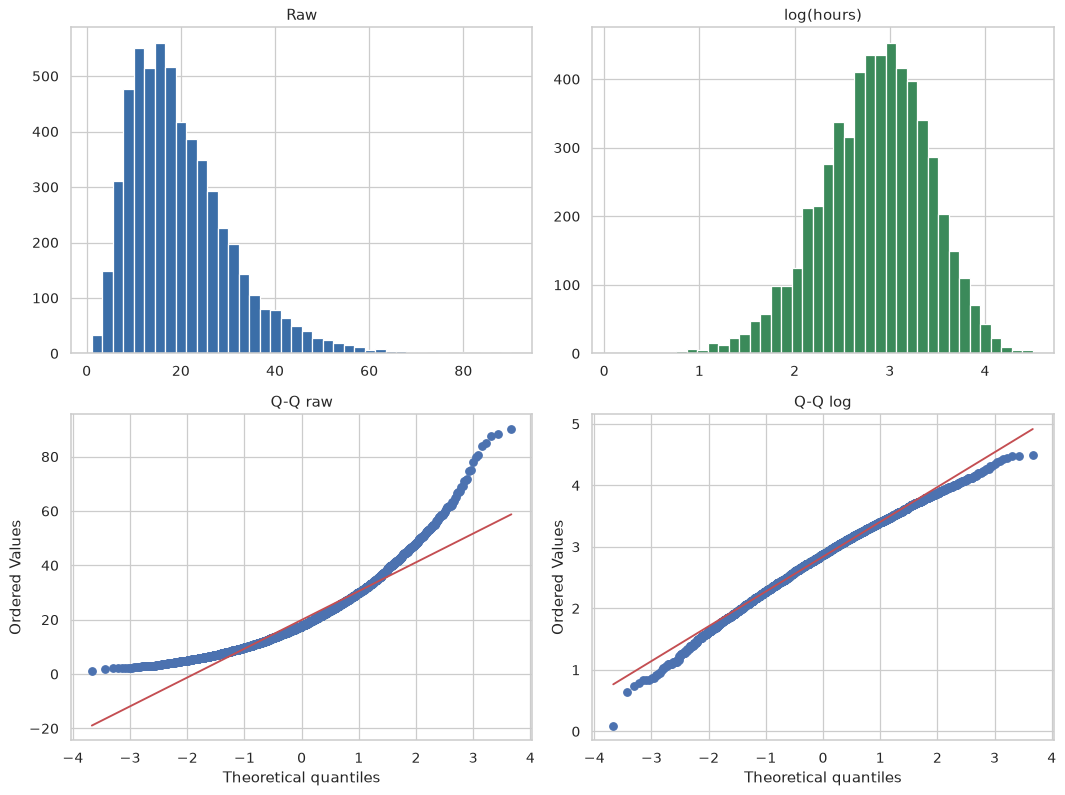

n = 5,672


,version,skew,excess_kurt,shapiro_W(n=1000),shapiro_p,dagostino_K2(full),dagostino_p
0,raw,1.333,2.925,0.918,7.29e-23,1407.621,2.182e-306
1,log,-0.352,0.202,0.986,2.151e-08,119.034,1.42e-26


Share of random sub-samples of the LOG variable that a normality test REJECTS, by sample size:


,sample_size,share_rejected
0,30,0.15
1,100,0.26
2,500,0.82
3,2000,1.00
4,5672,1.00


In [44]:
# Q30
x = df.avg_resolution_hrs.dropna(); lx = np.log(x); rng = np.random.default_rng(42)
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0,0].hist(x, bins=40, color='#3b6ea8'); axes[0,0].set_title('Raw'); axes[0,1].hist(lx, bins=40, color='#3b8a5a'); axes[0,1].set_title('log(hours)')
stats.probplot(x, plot=axes[1,0]); axes[1,0].set_title('Q-Q raw'); stats.probplot(lx, plot=axes[1,1]); axes[1,1].set_title('Q-Q log'); plt.tight_layout(); plt.show()
rows = []
for name, v in [('raw', x), ('log', lx)]:
    sw = stats.shapiro(v.sample(1000, random_state=1)); da = stats.normaltest(v)
    rows.append([name, v.skew(), v.kurt(), sw.statistic, sw.pvalue, da.statistic, da.pvalue])
res = pd.DataFrame(rows, columns=['version','skew','excess_kurt','shapiro_W(n=1000)','shapiro_p','dagostino_K2(full)','dagostino_p']); res['shapiro_p'] = res.shapiro_p.map(p4); res['dagostino_p'] = res.dagostino_p.map(p4)
print(f'n = {len(x):,}'); display(res.round(3))
rows = []
for n_ in [30, 100, 500, 2000, len(lx)]:
    p_ = np.mean([stats.normaltest(lx.sample(n_, random_state=i))[1] < ALPHA for i in range(200)]) if n_ >= 30 and n_ < len(lx) else float(stats.normaltest(lx)[1] < ALPHA)
    rows.append([n_, p_])
print('Share of random sub-samples of the LOG variable that a normality test REJECTS, by sample size:')
display(pd.DataFrame(rows, columns=['sample_size','share_rejected']).round(2))

 avg_resolution_hrs is not normal (skew 1.33; Shapiro-Wilk on 1,000 points p = 7.3e-23; D'Agostino p = 2.2e-306; the Q-Q plot curves upward at the right). The log transform helps a lot — skew falls to −0.35 and excess kurtosis to 0.2, and the Q-Q plot is almost a straight line — yet the tests still "reject" (p ≈ 1e-8 to 1e-26).

What sample size does: with the log variable, a normality test rejects only 15% of random samples at n = 30 and 26% at n = 100, but 82% at n = 500 and 100% at n ≥ 2,000. Small samples can hide real non-normality; large samples flag trivial departures. So judge normality by Q-Q plot, skew and kurtosis, not by p-value alone — the log-scale data is close enough to normal for practical use (for example, ANOVA on log-hours). 

(vi) Business conclusion: Resolution times have a long tail of slow cases, so report medians (or analyse the log) rather than the average alone.

### Part D — RECOMMENDATION TO THE CEO 

31. One-page memo to Ms. Deshmukh: which of the seven board claims are supported, which are rejected, and which have no support in the data. Rank the top three levers for reducing churn, and estimate in rupees what a 5-percentage-point drop in churn is worth per year (use the ₹2,400 replacement cost; you may also count retained monthly revenue).

Please find in CEO_memo.pdf

#### 32. Name two things this data cannot tell you (for example: causation vs association, the pilot had no control group, why "significant" is easy at n ≈ 6,000) and what data you would ask for next.

1. **Causation vs association.** Everything here is observational. OTT, AutoPay, routers and contracts are chosen by or assigned to different kinds of customers, and our adjustments only control for what we measured. CSAT and ticket counts may also be symptoms of a customer already leaving (reverse causality). The router pilot had no control group (Pune only, non-random, and some pilot customers still show an old router in the extract), so the June→October gain could partly be seasonal or network-wide. A model scenario like "−5.5 pp" is a direction, not a promise.

2. **"Significant" is easy at n ≈ 6,000** A ₹21 gap in ARPU (2.2%, p = 1.8e-05) and a 0.16-point CSAT gap between plans (p = 0.002) are statistically significant yet too small to act on. Conversely, the pilot has only 180 customers, so small effects there are uncertain. Always read effect sizes and confidence intervals, not p-values alone.

3. (Also) We cannot see why customers leave — only that they did, within one 12-month window, with features measured at a single point in time.